## 1. Significant earthquakes since 2150 B.C.
```text
The Significant Earthquake Database contains information on destructive earthquakes from 2150 B.C. to the present. On the top left corner, select all columns and download the entire significant earthquake data file in .tsv format by clicking the Download TSV File button. Click the variable name for more information. Read the file (e.g., earthquakes-2026-10-14_11-23-28_+0800.tsv) as an object and name it Sig_Eqs.

In [274]:
##加载包
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
## 读入数据
Sig_Eqs = pd.read_csv(r"earthquakes-2026-10-15_11-41-18_+0800.tsv", sep="\t")
print(Sig_Eqs.info())
print(Sig_Eqs.head())

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

In [275]:
##结合下面的题目，其实只有几列需要被用到Total deaths,Country,Ms,Mw,Location name和时间 Year,Mo,Dy,单独截一下
Sig_Eqs = Sig_Eqs[['Year','Mo','Dy','Total Deaths','Country','Ms','Location Name','Mw']]

**1.1 [5 points]** Compute the total number of deaths caused by earthquakes since 2150 B.C. in each country, and then print the top 20 countries along with the total number of deaths.

In [276]:
## 查看一下国家是怎么表示的
print(Sig_Eqs['Country'])

0                NaN
1             JORDAN
2              SYRIA
3       TURKMENISTAN
4             GREECE
            ...     
6693           JAPAN
6694     PHILIPPINES
6695        COLOMBIA
6696       INDONESIA
6697          PANAMA
Name: Country, Length: 6698, dtype: str


In [277]:
## 去除缺失值
Sig_Eqs_country = Sig_Eqs[~Sig_Eqs['Country'].isna()]

In [278]:
##统计总死亡人数，按国家分，并排出前20
print(Sig_Eqs_country.groupby('Country').sum()['Total Deaths'].sort_values(ascending=False).iloc[0:20])

Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64


**1.2 [10 points]** Compute the total number of earthquakes with magnitude larger than 3.0 (use column Ms as the magnitude) worldwide each year, and then plot the time series. Do you observe any trend? Explain why or why not?

In [279]:
##按年划分去统计
##先筛出Ms大于3的地震
Sig_Eqs_es = Sig_Eqs[Sig_Eqs['Ms'] > 3]

##随后按年分组统计次数
Sig_Eqs_es_year = Sig_Eqs_es.groupby('Year').size()
print(Sig_Eqs_es_year)

Year
-2000.0    1
-479.0     1
-426.0     1
-400.0     1
-373.0     1
          ..
 2015.0    1
 2017.0    1
 2019.0    1
 2024.0    1
 2025.0    3
Length: 511, dtype: int64


In [288]:
##注意到有较多年份其实没有发生地震或者说没有记录，考虑插值补充为0，方便图像绘制
##转为数据框绘图
df = Sig_Eqs_es_year.reset_index(name='Count')
for i in range(-2000,2027):
    if i not in df['Year'].values:
        df.loc[len(df)] = [i, 0]
df = df.sort_values('Year')
print(df)

        Year  Count
0    -2000.0      1
511  -1999.0      0
512  -1998.0      0
513  -1997.0      0
514  -1996.0      0
...      ...    ...
4024  2022.0      0
4025  2023.0      0
509   2024.0      1
510   2025.0      3
4026  2026.0      0

[4027 rows x 2 columns]


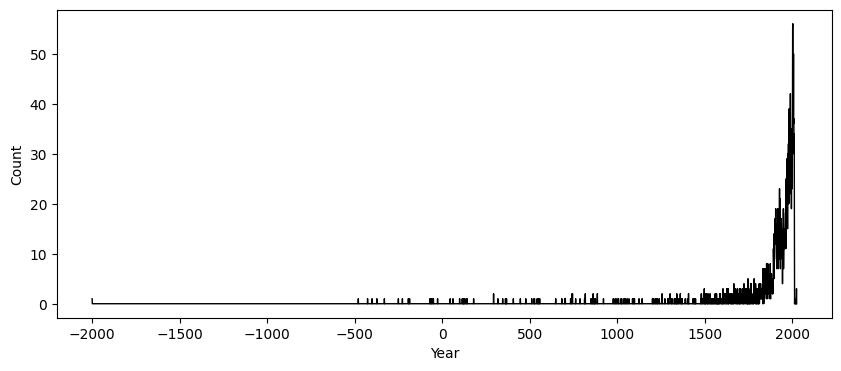

In [289]:
##画时间趋势图
plt.figure(figsize=(10, 4))
plt.plot(
    df['Year'],
    df['Count'],
    color='black',
    linewidth=1
)
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()


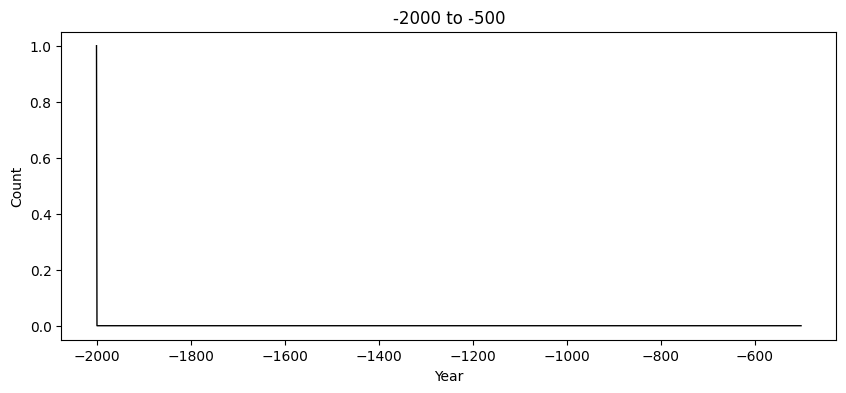

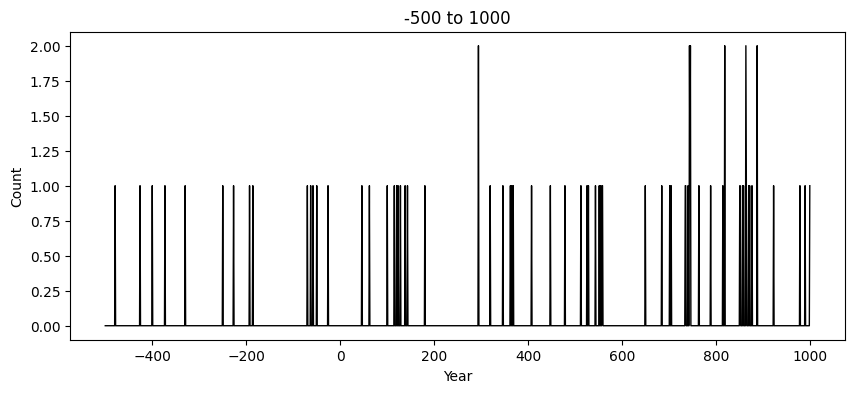

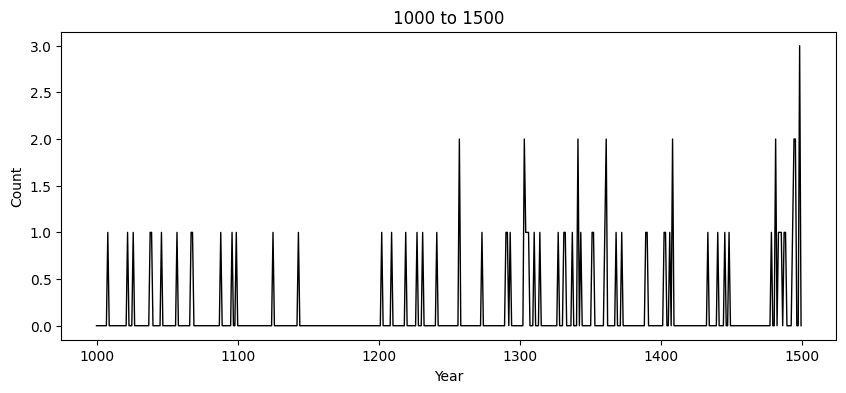

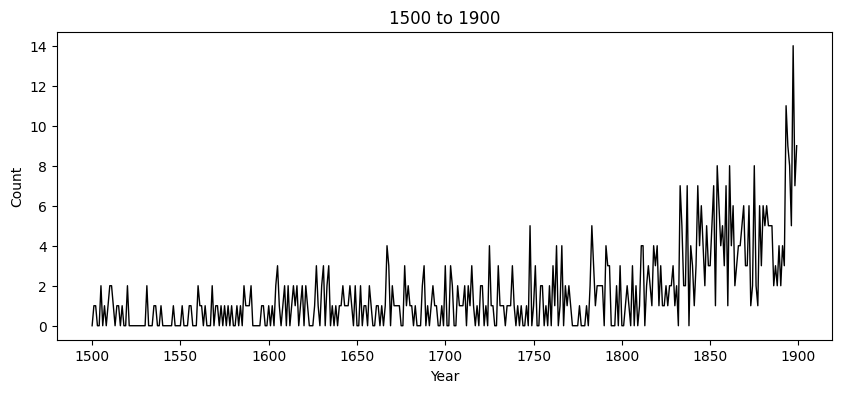

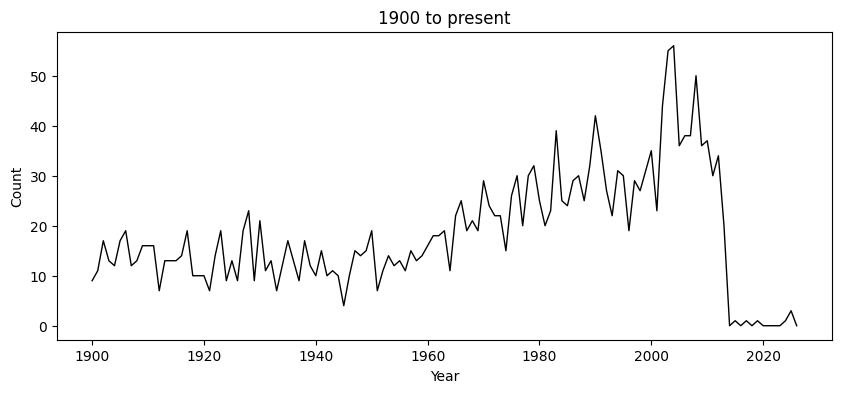

In [290]:
##注意到不同时间条件下地震计数情况明显不同，看看不同时间段内的情况
##分为五个时间段，-2000到-500为一张图，-500到1000为一张图，1000-1500为一张图，
# 1500-1900为一张图，1900-现在为一张图

range_case = [
    (-2000, -500, '-2000 to -500'),
    (-500, 1000, '-500 to 1000'),
    (1000, 1500, '1000 to 1500'),
    (1500, 1900, '1500 to 1900'),
    (1900, 2027, '1900 to present')
]

for start, end, title in range_case:
    period_df = df[(df['Year'] >= start) & (df['Year'] < end)]
    plt.figure(figsize=(10, 4))
    plt.plot(period_df['Year'], period_df['Count'], color='black', linewidth=1)
    plt.title(title)
    plt.xlabel('Year')
    plt.ylabel('Count')
    plt.show()

In [291]:
##地震最多年份
print(df.loc[df['Count'] == df['Count'].max(), ['Year', 'Count']])

       Year  Count
496  2004.0     56


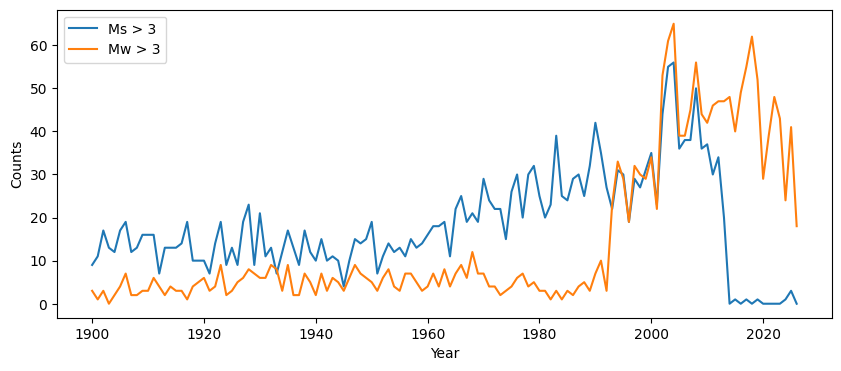

In [292]:
##MW的记录情况
#1900年后的数据
eq_compare = Sig_Eqs.loc[Sig_Eqs['Year'] >= 1900]
# 分别统计每年 Ms > 3 和 Mw > 3 的记录数
Ms_count = eq_compare.loc[eq_compare['Ms'] > 3].groupby('Year').size()
Mw_count = eq_compare.loc[eq_compare['Mw'] > 3].groupby('Year').size()
compare_count = pd.DataFrame({
    'Ms_count': Ms_count,
    'Mw_count': Mw_count
}).fillna(0).reset_index()
# 用折线图对比两种震级的年度记录数
plt.figure(figsize=(10, 4))
plt.plot(compare_count['Year'], compare_count['Ms_count'], label='Ms > 3')
plt.plot(compare_count['Year'], compare_count['Mw_count'], label='Mw > 3')
plt.xlabel('Year')
plt.ylabel('Counts')
plt.legend()
plt.show()


**1.3 [10 points]** Write a function CountEq_LargestEq that returns (a) the total number of earthquakes since 2150 B.C. in a given country AND (b) date and location of the largest earthquake ever happened in this country. Apply CountEq_LargestEq to every country in the file, report your results in a descending order.

In [174]:
##定义函数，给定国家，返回自2150 B.C.以来国家发生地震的次数以及这个国家发生的最大的地震的具体地点和时间
def CountEq_LargestEq(Cty):
    ##统一把国家换成大写字母，防止有人输入小写字母
    ##因为数据集看起来国家大部分是大写字母，所以统一格式
    Cty = Cty.upper()
    Sig_Eqs_country['Country'] = Sig_Eqs_country['Country'].str.upper()
    # 筛选出指定国家的地震数据
    country_eqs = Sig_Eqs_country[Sig_Eqs_country['Country'] == Cty]
    # 计算地震次数
    eq_count = len(country_eqs)
    # 找到最大的地震发生的信息
    largest_eq = country_eqs.sort_values(by='Ms', ascending=False).iloc[0]

    # 要分几种情况讨论
    # 如果这个最大的地震连震级都没有，而且发生次数在2次以上，那么地区就无法确定
    if pd.isna(largest_eq['Ms']) and eq_count >= 2:
        return [eq_count, '未知时间', '未知地点', '未记录']

    # 如果这个最大的地震没有震级，但是就他这一条记录，那么地区可以确定
    # 这种情况可以继续
    # 获取最大地震的具体地点和时间
    largest_eq_location = largest_eq['Location Name'] 
    ##如果年份未NA值
    if pd.isna(largest_eq['Year']):
        largest_eq_time = '未记录'
    ##如果月份为NA值（不管日期是否NA）都只输出年份
    elif pd.isna(largest_eq['Mo']):
        largest_eq_time = str(int(largest_eq['Year'])) + '年'
    ##如果只有日期为NA值
    elif pd.isna(largest_eq['Dy']):
        largest_eq_time = str(int(largest_eq['Year'])) + '年' + str(int(largest_eq['Mo'])) + '月'
    else:
        largest_eq_time = str(int(largest_eq['Year'])) + '年' + str(int(largest_eq['Mo'])) + '月' + str(int(largest_eq['Dy'])) + '日'
    ##返回震级，三目判断是否为NAN值
    largest_Ms = '为'+str(largest_eq['Ms'])+'级' if not pd.isna(largest_eq['Ms']) else '未记录'
    

    
    return [eq_count, largest_eq_time, largest_eq_location, largest_Ms]

##调用函数，并根据返回结果按要求中文输出结果:
res = CountEq_LargestEq("India")
print("自2150 B.C.以来共发生地震" + str(res[0]) + "次。")
print("其中最大的地震发生在" + res[1] + "，地点为" + res[2] + "，震级" + res[3]+'。')



res = CountEq_LargestEq("SAINT VINCENT AND THE GRENADINES")
print("自2150 B.C.以来共发生地震" + str(res[0]) + "次。")
print("其中最大的地震发生在" + res[1] + "，地点为" + res[2] + "，震级" + res[3] +'。')


自2150 B.C.以来共发生地震102次。
其中最大的地震发生在1897年6月12日，地点为INDIA:  ASSAM; BANGLADESH，震级为8.7级。
自2150 B.C.以来共发生地震1次。
其中最大的地震发生在1844年8月30日，地点为SAINT VINCENT:  KINGSTOWN，震级未记录。


In [175]:
##对所有国家都应用一遍，但是要降序输出,先找到国家地震次数降序
Sig_Eqs_country_count = Sig_Eqs_country.groupby('Country').size().sort_values(ascending=False)
#print(Sig_Eqs_country_count)

##然后按上述顺序遍历
for cty in Sig_Eqs_country_count.index:
    res = CountEq_LargestEq(cty)
    print("国家: " + cty)
    print("自2150 B.C.以来共发生地震" + str(res[0]) + "次。")
    print("其中最大的地震发生在" + res[1] + "，地点为" + res[2] + "，震级" + res[3] +'。')
    print()

国家: CHINA
自2150 B.C.以来共发生地震626次。
其中最大的地震发生在1920年12月16日，地点为CHINA:  GANSU PROVINCE, SHANXI PROVINCE，震级为8.6级。

国家: JAPAN
自2150 B.C.以来共发生地震429次。
其中最大的地震发生在869年7月13日，地点为JAPAN:  SANRIKU，震级为8.6级。

国家: INDONESIA
自2150 B.C.以来共发生地震427次。
其中最大的地震发生在2004年12月26日，地点为INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST，震级为8.8级。

国家: IRAN
自2150 B.C.以来共发生地震385次。
其中最大的地震发生在856年12月22日，地点为IRAN:  DAMGHAN, QUMIS，震级为7.9级。

国家: TURKEY
自2150 B.C.以来共发生地震359次。
其中最大的地震发生在1999年8月17日，地点为TURKEY:  ISTANBUL, KOCAELI, SAKARYA，震级为7.8级。

国家: ITALY
自2150 B.C.以来共发生地震338次。
其中最大的地震发生在1915年1月13日，地点为ITALY:  MARSICA, AVEZZANO, ABRUZZI，震级为7.5级。

国家: GREECE
自2150 B.C.以来共发生地震296次。
其中最大的地震发生在365年7月21日，地点为GREECE:  CRETE:  KNOSSOS，震级为8.0级。

国家: USA
自2150 B.C.以来共发生地震283次。
其中最大的地震发生在1957年3月9日，地点为ALASKA，震级为9.1级。

国家: PHILIPPINES
自2150 B.C.以来共发生地震233次。
其中最大的地震发生在1897年9月21日，地点为PHILIPPINES:  MINDANAO, ZAMBOANGA, SULU, ISABELA，震级为8.7级。

国家: MEXICO
自2150 B.C.以来共发生地震217次。
其中最大的地震发生在1787年3月28日，地点为MEXICO:  SAN MARCOS, OAXACA，震级为8.3级。

国家: CHILE
自2150 B.C

## 2. Air temperature in Shenzhen 1998-2022
```text
In this problem set, we will examine how air temperature changes in Shenzhen from 1998 to 2022 using the hourly weather data measured at the Baoan International Airport. The data set is from NOAA Integrated Surface Dataset. Download the zipped file Baoan_Weather_1998_2022.zip, unzip it, and move the Baoan_Weather_1998_2022.csv file to your working directory.

Read page 10-11 (POS 88-92 and POS 93-93) of the comprehensive user guide for the detailed format of the air temperature data (use column TMP). Explain how you filter the data in your report.
```
**[10 points]** Plot monthly averaged air temperature against the observation time. Is there a trend in monthly averaged air temperature from 1998 to 2022?

In [220]:
import pandas as pd
import matplotlib.pyplot as plt

## 读取宝安机场数据
AT = pd.read_csv('Baoan_Weather_1998_2022.csv')

##看个大概
print(AT.info())
print(AT.head(5))

##列名
print(AT.columns)

C:\Users\55471\AppData\Local\Temp\ipykernel_37348\433714496.py:5: DtypeWarning: Columns (4: CALL_SIGN, 8: AA3, 9: AG1, 10: AJ1, 11: AW1, 14: AZ1, 15: CALL_SIGN.1, 24: GA5, 25: GE1, 27: HL1, 29: IA2, 31: KA2, 34: ME1, 37: MW3, 38: OA1, 40: OD1, 41: OD2, 45: SA1, 49: UA1, 50: UG1) have mixed types. Specify dtype option on import or set low_memory=False.


<class 'pandas.DataFrame'>
RangeIndex: 235674 entries, 0 to 235673
Data columns (total 54 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   STATION            235674 non-null  int64  
 1   DATE               235674 non-null  str    
 2   SOURCE             235674 non-null  int64  
 3   REPORT_TYPE        235674 non-null  str    
 4   CALL_SIGN          235674 non-null  object 
 5   QUALITY_CONTROL    235674 non-null  str    
 6   AA1                24482 non-null   str    
 7   AA2                5923 non-null    str    
 8   AA3                3207 non-null    str    
 9   AG1                7307 non-null    str    
 10  AJ1                679 non-null     str    
 11  AW1                3 non-null       str    
 12  AY1                15557 non-null   str    
 13  AY2                9200 non-null    str    
 14  AZ1                3 non-null       str    
 15  CALL_SIGN.1        235674 non-null  object 
 16  CIG          

In [176]:
## 实际上我们只关心温度，所以把AT数据里的温度筛出来就行，剩下的都是无用变量
## 'DATE'和'TMP'有用
AT_cut = AT[['DATE','TMP']]
print(AT_cut)

                       DATE      TMP
0       1998-01-01T00:00:00  +0186,1
1       1998-01-01T01:00:00  +0220,1
2       1998-01-01T02:00:00  +0240,1
3       1998-01-01T03:00:00  +0221,1
4       1998-01-01T04:00:00  +0240,1
...                     ...      ...
235669  2022-10-10T20:00:00  +0210,1
235670  2022-10-10T21:00:00  +0201,1
235671  2022-10-10T21:00:00  +0200,1
235672  2022-10-10T22:00:00  +0200,1
235673  2022-10-10T23:00:00  +0200,1

[235674 rows x 2 columns]


In [177]:
##去除数据缺失值，即+9999的温度
##此外还要考虑数据质量，1和5是可以接受的数据
##把TMP根据逗号进行分列
AT_cut['TMP_value'] = AT_cut['TMP'].str.split(',').str[0]
AT_cut['TMP_quality'] = AT_cut['TMP'].str.split(',').str[1]
##需要筛除不好的数据
AT_cut = AT_cut.loc[((AT_cut['TMP_quality']=='1') | (AT_cut['TMP_quality']=='5')) & (AT_cut['TMP_value']!='+9999')]
print(AT_cut)

                       DATE      TMP TMP_value TMP_quality
0       1998-01-01T00:00:00  +0186,1     +0186           1
1       1998-01-01T01:00:00  +0220,1     +0220           1
2       1998-01-01T02:00:00  +0240,1     +0240           1
3       1998-01-01T03:00:00  +0221,1     +0221           1
4       1998-01-01T04:00:00  +0240,1     +0240           1
...                     ...      ...       ...         ...
235669  2022-10-10T20:00:00  +0210,1     +0210           1
235670  2022-10-10T21:00:00  +0201,1     +0201           1
235671  2022-10-10T21:00:00  +0200,1     +0200           1
235672  2022-10-10T22:00:00  +0200,1     +0200           1
235673  2022-10-10T23:00:00  +0200,1     +0200           1

[234864 rows x 4 columns]


In [178]:
#TMP_value有一个scaling factor10，所以应该除以10
#pd.to_numeric可以把series格式转换成数字
AT_cut['TMP_value'] = pd.to_numeric(AT_cut['TMP_value'])/10

In [179]:
# 读取观测的时间
AT_cut['DATE'] = pd.to_datetime(AT['DATE'])
AT_cut['DATE_spe'] = AT_cut['DATE'].dt.strftime('%Y-%m')
print(AT_cut)

                      DATE      TMP  TMP_value TMP_quality DATE_spe
0      1998-01-01 00:00:00  +0186,1       18.6           1  1998-01
1      1998-01-01 01:00:00  +0220,1       22.0           1  1998-01
2      1998-01-01 02:00:00  +0240,1       24.0           1  1998-01
3      1998-01-01 03:00:00  +0221,1       22.1           1  1998-01
4      1998-01-01 04:00:00  +0240,1       24.0           1  1998-01
...                    ...      ...        ...         ...      ...
235669 2022-10-10 20:00:00  +0210,1       21.0           1  2022-10
235670 2022-10-10 21:00:00  +0201,1       20.1           1  2022-10
235671 2022-10-10 21:00:00  +0200,1       20.0           1  2022-10
235672 2022-10-10 22:00:00  +0200,1       20.0           1  2022-10
235673 2022-10-10 23:00:00  +0200,1       20.0           1  2022-10

[234864 rows x 5 columns]


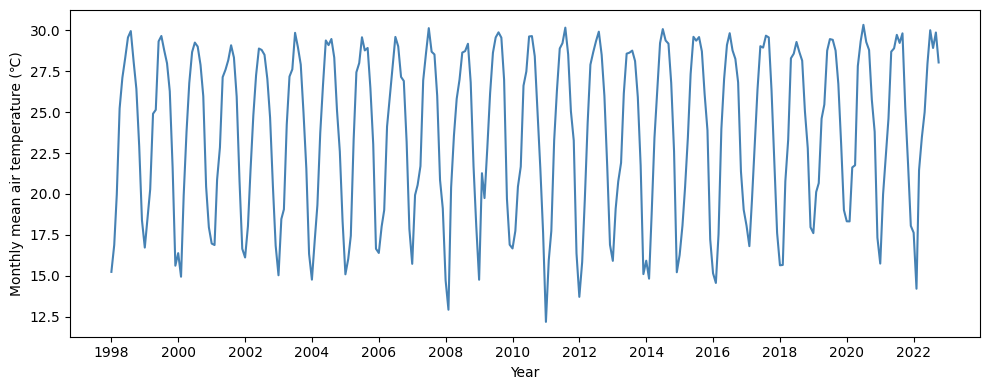

In [185]:
# 按年月计算月平均空气温度
monthly_temperature = AT_cut.groupby('DATE_spe')['TMP_value'].mean()
monthly_temperature.index = pd.to_datetime(monthly_temperature.index)

# 年平均温度用于辅助判断长期变化
#annual_temperature = AT.groupby(AT['DATE'].dt.year)['Air_Temperature'].mean()
#print(annual_temperature.head())
#print(annual_temperature.tail())

# 绘制月平均温度时间序列
plt.figure(figsize=(10, 4))
plt.plot(monthly_temperature.index, monthly_temperature.values, color='steelblue')
tick_years = range(
    monthly_temperature.index.min().year,
    monthly_temperature.index.max().year + 1,
    2
)
tick_dates = pd.to_datetime([str(year) + '-01-01' for year in tick_years])
plt.xticks(tick_dates, [str(year) for year in tick_years])
plt.xlabel('Year')
plt.ylabel('Monthly mean air temperature (℃)')
plt.show()


## 3. Global collection of hurricanes
```text 
The International Best Track Archive for Climate Stewardship (IBTrACS) project is the most complete global collection of tropical cyclones available. It merges recent and historical tropical cyclone data from multiple agencies to create a unified, publicly available, best-track dataset that improves inter-agency comparisons. IBTrACS was developed collaboratively with all the World Meteorological Organization (WMO) Regional Specialized Meteorological Centers, as well as other organizations and individuals from around the world.

In this problem set, we will use all storms available in the IBTrACS record since 1842. Download the zipped file ibtracs.ALL.list.v04r00.zip, unzip it, and move the ibtracs.ALL.list.v04r00.csv file to your working directory. Read Column Variable Descriptions for variables in the file. Examine the first few lines of the file.

Below we provide an example to load the file as a pandas dataframe. Think about the options being used and why, and modify when necessary.
```
```python
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])
df.head()
```

In [219]:
import pandas as pd
import matplotlib.pyplot as plt

## 读前几行看看
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv')
print(df.info())
print(df.head())
##一共有163列,700000行
##第一行是单位，可以去掉

C:\Users\55471\AppData\Local\Temp\ipykernel_37348\3443310435.py:5: DtypeWarning: Columns (1: SEASON, 2: NUMBER, 8: LAT, 9: LON, 14: DIST2LAND, 19: USA_LAT, 20: USA_LON, 161: STORM_SPEED, 162: STORM_DIR) have mixed types. Specify dtype option on import or set low_memory=False.


<class 'pandas.DataFrame'>
RangeIndex: 707178 entries, 0 to 707177
Columns: 163 entries, SID to STORM_DIR
dtypes: int64(1), object(9), str(153)
memory usage: 879.4+ MB
None
             SID SEASON NUMBER BASIN SUBBASIN       NAME             ISO_TIME  \
0                  Year                                                         
1  1842298N11080   1842      1    NI       BB  NOT_NAMED  1842-10-25 03:00:00   
2  1842298N11080   1842      1    NI       BB  NOT_NAMED  1842-10-25 06:00:00   
3  1842298N11080   1842      1    NI       BB  NOT_NAMED  1842-10-25 09:00:00   
4  1842298N11080   1842      1    NI       BB  NOT_NAMED  1842-10-25 12:00:00   

  NATURE            LAT           LON  ... BOM_GUST_PER REUNION_GUST  \
0         degrees_north  degrees_east  ...       second          kts   
1     NR        10.9000       80.3000  ...                             
2     NR        10.8709       79.8265  ...                             
3     NR        10.8431       79.3524  ...          

In [234]:
## 读取 IBTrACS 数据
# 只保留完成下面几题需要的字段
# SID：风暴的ID；
# NAME：风暴名称；
# WMO_WIND：风速（单位：节，kts），不同地区统计方式不一样，但不影响值。
# BASIN：风暴所属区域；
# ISO_TIME：观测时间（UTC时间）；
# LAT：纬度（北纬为正）；
# LON：经度（东经为正）。
usecols = ['SID', 'NAME', 'WMO_WIND', 'BASIN', 'ISO_TIME', 'LAT', 'LON']
#parse_dates读取数据时，直接将ISO-TIME解析为时间
##把NOT_NAMED识别为缺失值NaN，此外注意到WMO_WIND里面也有空白字符
df = pd.read_csv(
    'ibtracs.ALL.list.v04r00.csv',
    usecols=usecols,
    skiprows=[1],
    parse_dates=['ISO_TIME'],
    na_values=['NOT_NAMED',' '],
    low_memory=False
)
#风速转为数值
df['WMO_WIND'] = pd.to_numeric(df['WMO_WIND'])
print(df.head())

             SID BASIN NAME            ISO_TIME      LAT      LON  WMO_WIND
0  1842298N11080    NI  NaN 1842-10-25 03:00:00  10.9000  80.3000       NaN
1  1842298N11080    NI  NaN 1842-10-25 06:00:00  10.8709  79.8265       NaN
2  1842298N11080    NI  NaN 1842-10-25 09:00:00  10.8431  79.3524       NaN
3  1842298N11080    NI  NaN 1842-10-25 12:00:00  10.8188  78.8772       NaN
4  1842298N11080    NI  NaN 1842-10-25 15:00:00  10.8000  78.4000       NaN


**3.1 [5 points]** Group the data on Storm Identifie (SID), report names (NAME) of the 10 largest hurricanes according to wind speed (WMO_WIND).

In [225]:
## 确定最大风速
storms = df.groupby('SID')['WMO_WIND'].max().dropna()
storms_10 = storms.sort_values(
    ascending=False
).head(10).reset_index(name='WMO_WIND')

# 根据SID确定名字
storms_10_name = df.loc[
    df['SID'].isin(storms_10['SID']), ['SID', 'NAME']
].drop_duplicates(subset='SID')

# 合并回名称
storms_10 = storms_10.merge(storms_10_name, on='SID', how='left')
storms_10 = storms_10[['SID', 'NAME', 'WMO_WIND']]
print(storms_10)


             SID      NAME  WMO_WIND
0  2015293N13266  PATRICIA     185.0
1  1980214N11330     ALLEN     165.0
2  2019236N10314    DORIAN     160.0
3  1988253N12306   GILBERT     160.0
4  2005289N18282     WILMA     160.0
5  1935241N23291       NaN     160.0
6  1997253N12255     LINDA     160.0
7  2017242N16333      IRMA     155.0
8  1998295N12284     MITCH     155.0
9  2009288N07267      RICK     155.0


**3.2 [5 points]** List the wind speed (WMO_WIND) of the 20 strongest-wind hurricanes.

In [226]:
##要求根据风速列出最强的20个风暴，好像和上一题没区别
storms = df.groupby('SID')['WMO_WIND'].max().dropna()
storms_20 = storms.sort_values(
    ascending=False
).head(20).reset_index(name='WMO_WIND')

#根据SID去找对应的名字，然后去重
storms_20_name = df.loc[
    df['SID'].isin(storms_20['SID']), ['SID', 'NAME']
].drop_duplicates(subset='SID')

#合并SID和名字
storms_20 = storms_20.merge(storms_20_name, on='SID', how='left')
storms_20 = storms_20[['SID', 'NAME', 'WMO_WIND']]
print(storms_20)


              SID      NAME  WMO_WIND
0   2015293N13266  PATRICIA     185.0
1   1980214N11330     ALLEN     165.0
2   2019236N10314    DORIAN     160.0
3   1988253N12306   GILBERT     160.0
4   2005289N18282     WILMA     160.0
5   1935241N23291       NaN     160.0
6   1997253N12255     LINDA     160.0
7   2017242N16333      IRMA     155.0
8   1998295N12284     MITCH     155.0
9   2009288N07267      RICK     155.0
10  2005261N21290      RITA     155.0
11  1955265N13307     JANET     150.0
12  1992230N11325    ANDREW     150.0
13  2016041S14170   WINSTON     150.0
14  1977242N27272     ANITA     150.0
15  2017260N12310     MARIA     150.0
16  2005236N23285   KATRINA     150.0
17  1959249N19181     PATSY     150.0
18  1979238N12324     DAVID     150.0
19  1994222N11267      JOHN     150.0


**3.3 [5 points]** Count all datapoints by Basin.

In [ ]:
##按Basin统计数据点
##去掉缺失值MM，可能没有
basin_counts = df.loc[df['BASIN']!='MM'].groupby('BASIN').size()
print(basin_counts)
##只剩下583000条数据，少了120000条，而且NA被去掉了

BASIN
EP     62412
NI     55402
SA       119
SI    160668
SP     67119
WP    236576
dtype: int64


In [241]:
##文档中说明NA是North Atlantic，所以统计时不应该去掉NA
##但是又担心文档有些真的是NA值，而不是MM值，他写文档时有疏漏
##这里只考虑统计basin的话，读取文档时先不要去掉NA
df_2 = pd.read_csv(
     'ibtracs.ALL.list.v04r00.csv',
        usecols=usecols,
        skiprows=[1],
        parse_dates=['ISO_TIME'],
         keep_default_na=False,
        na_values=['NOT_NAMED',' '],
        low_memory=False
)
basin_counts = df_2.loc[df_2['BASIN']!='MM'].groupby('BASIN').size()
print(basin_counts)


BASIN
EP     62412
NA    124881
NI     55402
SA       119
SI    160668
SP     67119
WP    236576
dtype: int64


**3.4 [5 points]** Make a hexbin plot of the location of datapoints in Latitude and Longitude.

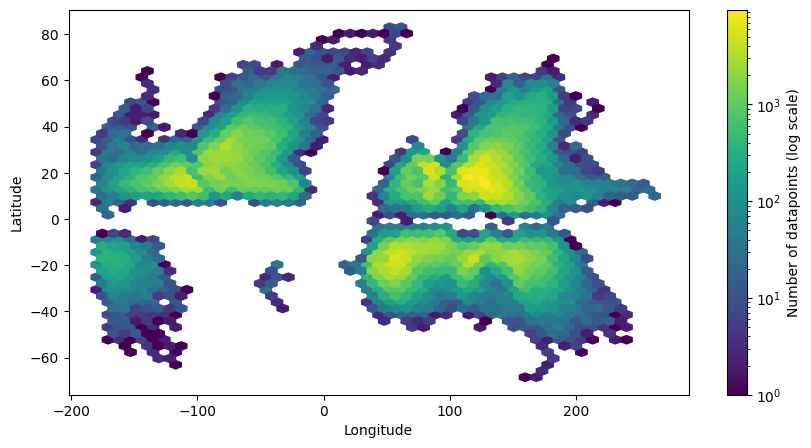

In [236]:
## 经纬度Hexbin图
## 去掉经纬度的na值
location_df = df.loc[
    df['LAT'].notna() & df['LON'].notna()
]
##因为点差距较大，画对数图可能比较明显
plt.figure(figsize=(10, 4))
plt.hexbin(
    location_df['LON'], location_df['LAT'],
    bins='log', gridsize=50, cmap='viridis'
)
plt.colorbar(label='Number of datapoints (log scale)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


**3.5 [5 points]** Find Typhoon Mangkhut (from 2018) and plot its track.

In [198]:
##2018年台风筛选
mangkhut_2018 = df.loc[
    (df['NAME'] == 'MANGKHUT') &
    (df['ISO_TIME'].dt.year == 2018)
]
print(mangkhut_2018.head())


                  SID BASIN      NAME            ISO_TIME      LAT      LON  \
683019  2018250N12170    WP  MANGKHUT 2018-09-06 12:00:00  11.8000  170.200   
683020  2018250N12170    WP  MANGKHUT 2018-09-06 15:00:00  11.9275  169.745   
683021  2018250N12170    WP  MANGKHUT 2018-09-06 18:00:00  12.0000  169.225   
683022  2018250N12170    WP  MANGKHUT 2018-09-06 21:00:00  12.0302  168.564   
683023  2018250N12170    WP  MANGKHUT 2018-09-07 00:00:00  12.0875  167.875   

        WMO_WIND  
683019       NaN  
683020       NaN  
683021       NaN  
683022       NaN  
683023       NaN  


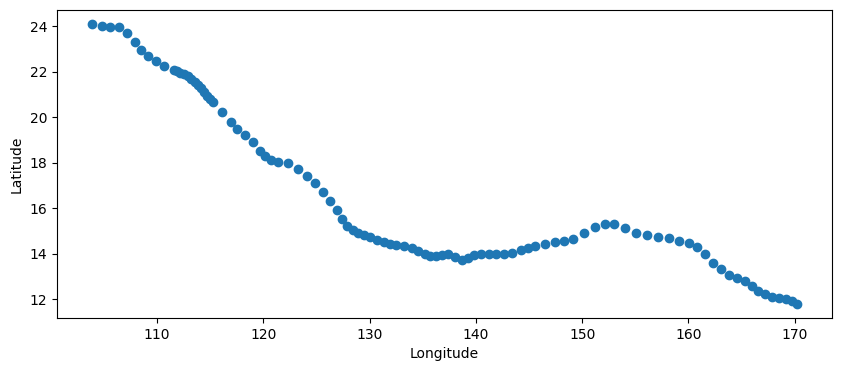

In [200]:
plt.figure(figsize=(10, 4))
plt.scatter(mangkhut_2018['LON'], mangkhut_2018['LAT'])
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


**3.6 [5 points]** Create a filtered dataframe that contains only data since 1970 from the Western North Pacific (“WP”) and Eastern North Pacific (“EP”) Basin. Use this for the rest of the problem set.

In [237]:
##只保留1970年后WP和EP的风暴
df_filter = df.loc[
    (df['ISO_TIME'].dt.year >= 1970) &
    ((df['BASIN'] == 'WP') | (df['BASIN'] == 'EP'))
]
print(df_filter.head())


                  SID BASIN   NAME            ISO_TIME      LAT      LON  \
350394  1970050N07151    WP  NANCY 1970-02-19 00:00:00  7.00000  151.400   
350395  1970050N07151    WP  NANCY 1970-02-19 03:00:00  7.24752  151.205   
350396  1970050N07151    WP  NANCY 1970-02-19 06:00:00  7.50000  151.000   
350397  1970050N07151    WP  NANCY 1970-02-19 09:00:00  7.75747  150.772   
350398  1970050N07151    WP  NANCY 1970-02-19 12:00:00  8.00000  150.500   

        WMO_WIND  
350394       NaN  
350395       NaN  
350396       NaN  
350397       NaN  
350398       NaN  


**3.7 [5 points]** Plot the number of datapoints per day.

In [238]:
##先提取每天的时间
df_filter['spe_time'] = df_filter['ISO_TIME'].dt.strftime('%Y-%m-%d')
print(df_filter['spe_time'])


350394    1970-02-19
350395    1970-02-19
350396    1970-02-19
350397    1970-02-19
350398    1970-02-19
             ...    
707085    2022-10-10
707086    2022-10-10
707174    2022-10-12
707175    2022-10-12
707176    2022-10-12
Name: spe_time, Length: 176352, dtype: str


In [239]:
##按天数分组统计
df_time = df_filter.groupby('spe_time').size().reset_index(name='count')
print(df_time)

         spe_time  count
0      1970-02-19      8
1      1970-02-20      8
2      1970-02-21      8
3      1970-02-22      8
4      1970-02-23      8
...           ...    ...
10812  2022-10-04      9
10813  2022-10-05      7
10814  2022-10-09      1
10815  2022-10-10      7
10816  2022-10-12      3

[10817 rows x 2 columns]


In [ ]:
##有些日期可能没有记录，我觉得应该不会有统计疏漏，所以这里以0补全
df_time['spe_time'] = pd.to_datetime(df_time['spe_time'])
start_date = df_time['spe_time'].min()
end_date = df_time['spe_time'].max()
date = start_date
while date <= end_date:
    if date not in df_time['spe_time'].values:
        df_time.loc[len(df_time)] = [date, 0]
    date = date + pd.Timedelta(days=1)
df_time = df_time.sort_values('spe_time')
print(df_time)


        spe_time  count
0     1970-02-19      8
1     1970-02-20      8
2     1970-02-21      8
3     1970-02-22      8
4     1970-02-23      8
...          ...    ...
19227 2022-10-08      0
10814 2022-10-09      1
10815 2022-10-10      7
19228 2022-10-11      0
10816 2022-10-12      3

[19229 rows x 2 columns]


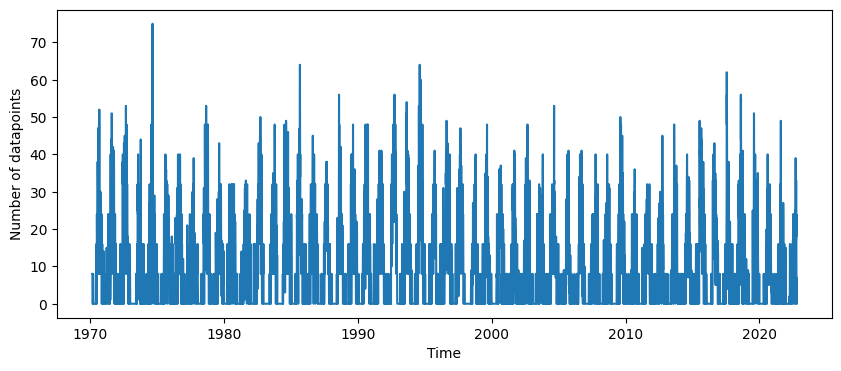

In [201]:
# 绘制每日数据点数量
plt.figure(figsize=(10, 4))
plt.plot(df_time['spe_time'], df_time['count'])
plt.xlabel('Time')
plt.ylabel('Number of datapoints')
plt.show()


**3.8 [5 points]** Calculate the climatology of datapoint counts as a function of day of year. The day of year is the sequential day number starting with day 1 on January 1st.

In [246]:
##要提取具体的日期，用当前的时间减去一月一号即可
df_time['day_of_year'] = 0

for i in df_time.index:
    date = df_time.loc[i, 'spe_time']
    first_day = pd.Timestamp(year=date.year, month=1, day=1)
    df_time.loc[i, 'day_of_year'] = (date - first_day).days + 1

#计算平均值，按年来划分，即各个年份每天数据点的均值
climatology = df_time.groupby('day_of_year')['count'].mean()
print(climatology)

day_of_year
1      1.596154
2      1.384615
3      1.423077
4      1.788462
5      2.019231
         ...   
362    3.038462
363    2.538462
364    2.000000
365    1.788462
366    1.000000
Name: count, Length: 366, dtype: float64


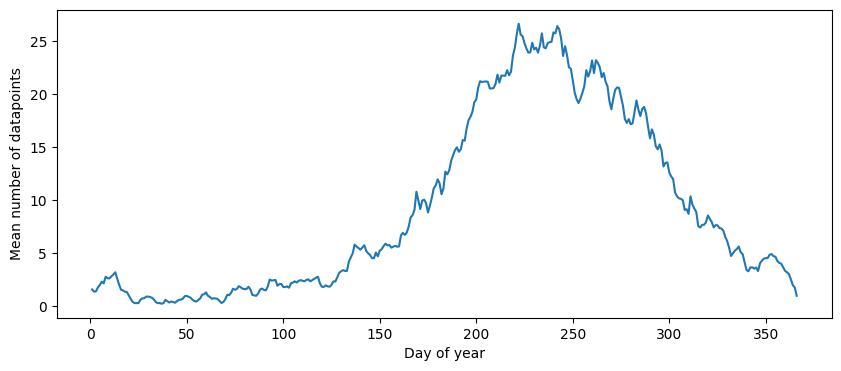

In [202]:
# 绘制按年内日序计算的气候态
plt.figure(figsize=(10, 4))
plt.plot(climatology.index, climatology.values)
plt.xlabel('Day of year')
plt.ylabel('Mean number of datapoints')
plt.show()


**3.9 [5 points]** Calculate the anomaly of daily counts from the climatology.

In [249]:
##扣去均值即可
df_time['anomaly'] = 0.0
for i in df_time.index:
    day = df_time.loc[i, 'day_of_year']
    df_time.loc[i, 'anomaly'] = df_time.loc[i, 'count'] - climatology.loc[day]
print(df_time[['spe_time', 'count', 'anomaly']])

        spe_time  count    anomaly
0     1970-02-19      8   7.018868
1     1970-02-20      8   7.094340
2     1970-02-21      8   7.188679
3     1970-02-22      8   7.377358
4     1970-02-23      8   7.490566
...          ...    ...        ...
19227 2022-10-08      0 -17.245283
10814 2022-10-09      1 -17.301887
10815 2022-10-10      7 -12.396226
19228 2022-10-11      0 -18.528302
10816 2022-10-12      3 -14.924528

[19229 rows x 3 columns]


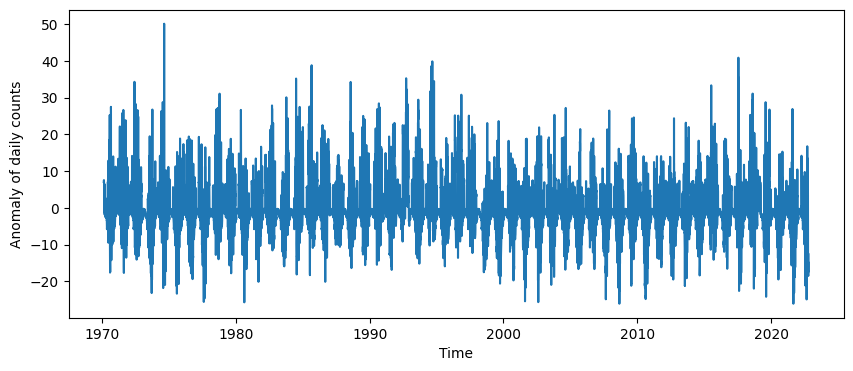

In [252]:
# 绘制每日计数异常
plt.figure(figsize=(10, 4))
plt.plot(df_time['spe_time'], df_time['anomaly'])
plt.xlabel('Time')
plt.ylabel('Anomaly of daily counts')
plt.show()


**3.10 [5 points]** Resample the anomaly timeseries at annual resolution and plot. So which years stand out as having anomalous hurricane activity?

In [77]:
## 3.10 在3.9的基础上，按年份去算平均的anomaly
df_time['Year'] = df_time['spe_time'].dt.year

# 计算每年的anomaly
annual_anomaly = df_time.groupby('Year')['anomaly'].mean()
print(annual_anomaly)

Year
1970    0.860986
1971    3.065001
1972    1.668648
1973   -2.556917
1974    0.659521
1975   -1.792533
1976   -0.000750
1977   -2.463766
1978    2.144453
1979   -0.387054
1980   -0.907854
1981   -0.724040
1982    1.645823
1983   -0.302122
1984    1.094878
1985    2.571850
1986    2.180069
1987   -0.337739
1988   -0.265778
1989    1.747193
1990    3.073220
1991    1.684179
1992    4.537501
1993    2.193768
1994    4.415686
1995   -0.477465
1996    2.433676
1997    3.330754
1998   -2.830890
1999   -2.425410
2000   -1.055395
2001   -1.239109
2002   -0.669246
2003   -1.310342
2004    0.297064
2005   -1.871985
2006   -0.633629
2007   -2.562396
2008   -1.918783
2009    0.338973
2010   -4.570616
2011   -2.069246
2012   -0.962499
2013   -0.893903
2014   -0.113081
2015    3.067741
2016   -0.582718
2017   -1.428150
2018    1.801987
2019   -0.080205
2020   -2.336816
2021   -2.751437
2022   -2.793204
Name: anomaly, dtype: float64


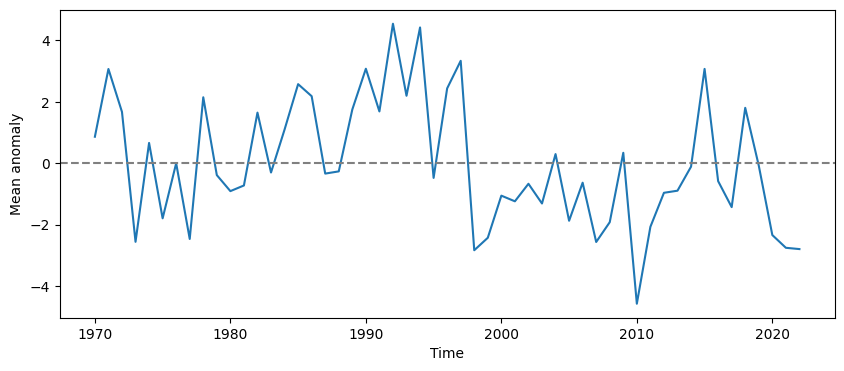

In [254]:
# 绘制年平均异常
plt.figure(figsize=(10, 4))
plt.plot(annual_anomaly.index, annual_anomaly.values)
plt.xlabel('Time')
plt.ylabel('Mean anomaly')
plt.axhline(0, color='gray', linestyle='--')
plt.show()


In [ ]:
highest_5 = annual_anomaly.sort_values(ascending=False).head(5)
lowest_5 = annual_anomaly.sort_values(ascending=True).head(5)

print('年平均异常值最高的五个年份：')
print(highest_5)
print()
print('年平均异常值最低的五个年份：')
print(lowest_5)


年平均异常值最高的五个年份：
Year
1992    4.537501
1994    4.415686
1997    3.330754
1990    3.073220
2015    3.067741
Name: anomaly, dtype: float64

年平均异常值最低的五个年份：
Year
2010   -4.570616
1998   -2.830890
2022   -2.793204
2021   -2.751437
2007   -2.562396
Name: anomaly, dtype: float64


## 4. Explore a data set
```text
Browse the National Centers for Environmental Information (NCEI) or Advanced Global Atmospheric Gases Experiment (AGAGE) website. Search and download a data set you are interested in. You are also welcome to use data from your group in this problem set. But the data set should be in csv, XLS, or XLSX format, and have temporal information.

**4.1 [5 points]** Load the csv, XLS, or XLSX file, and clean possible data points with missing values or bad quality.

In [263]:
import pandas as pd
import matplotlib.pyplot as plt
##加载北京首都国际机场的气象数据
##9999.9和999.9和99.99都是作为NA值
beijing = pd.read_csv(
    'beijing.csv',
    parse_dates=['DATE'],
    na_values=[9999.9, 999.9, 99.99]
)
##查看数据
print(beijing.info())
print(beijing.head())

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   STATION           366 non-null    int64         
 1   DATE              366 non-null    datetime64[us]
 2   LATITUDE          366 non-null    float64       
 3   LONGITUDE         366 non-null    float64       
 4   ELEVATION         366 non-null    float64       
 5   NAME              366 non-null    str           
 6   TEMP              366 non-null    float64       
 7   TEMP_ATTRIBUTES   366 non-null    int64         
 8   DEWP              366 non-null    float64       
 9   DEWP_ATTRIBUTES   366 non-null    int64         
 10  SLP               1 non-null      float64       
 11  SLP_ATTRIBUTES    366 non-null    int64         
 12  STP               0 non-null      float64       
 13  STP_ATTRIBUTES    366 non-null    int64         
 14  VISIB             366 non-null    flo

In [256]:
## 我们主要分析温度变化，这里去掉不存在的值
beijing_temp = beijing.loc[
    (beijing['DATE'].notna()) &
    (beijing['TEMP'].notna())
].copy().sort_values('DATE')

# 本来使用的温度是华氏度，这里将华氏度转换为摄氏度
beijing_temp['TEMP_C'] = (beijing_temp['TEMP'] - 32) / 1.8
## 方便后续按月份分析，这里提取出月份
beijing_temp['Month'] = beijing_temp['DATE'].dt.month

In [257]:
## TEMP_ATTRIBUTES列反应用来计算日均气温的数据点有多少个，可以反映数据质量
print(beijing['TEMP_ATTRIBUTES'].value_counts())
## 只有两个点小于24，但是为了日期数据完整性，这里考虑保留

TEMP_ATTRIBUTES
24    364
22      1
19      1
Name: count, dtype: int64


In [258]:
##我们只保留关键信息
beijing_temp = beijing_temp[['DATE', 'TEMP_C', 'Month']]
print(beijing_temp)

          DATE    TEMP_C  Month
0   2012-01-01 -2.833333      1
1   2012-01-02 -3.111111      1
2   2012-01-03 -5.055556      1
3   2012-01-04 -5.388889      1
4   2012-01-05 -5.277778      1
..         ...       ...    ...
361 2012-12-27 -8.444444     12
362 2012-12-28 -5.277778     12
363 2012-12-29 -5.055556     12
364 2012-12-30 -7.055556     12
365 2012-12-31 -6.500000     12

[366 rows x 3 columns]



**4.2 [5 points]** Plot the time series of a certain variable.


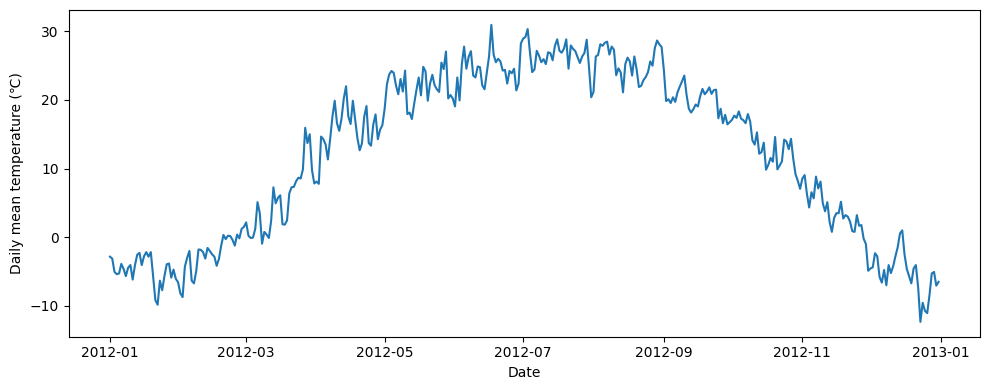

In [264]:
##绘制日均气温变化图
plt.figure(figsize=(10, 4))
plt.plot(beijing_temp['DATE'], beijing_temp['TEMP_C'])
plt.xlabel('Date')
plt.ylabel('Daily mean temperature (℃)')
plt.show()


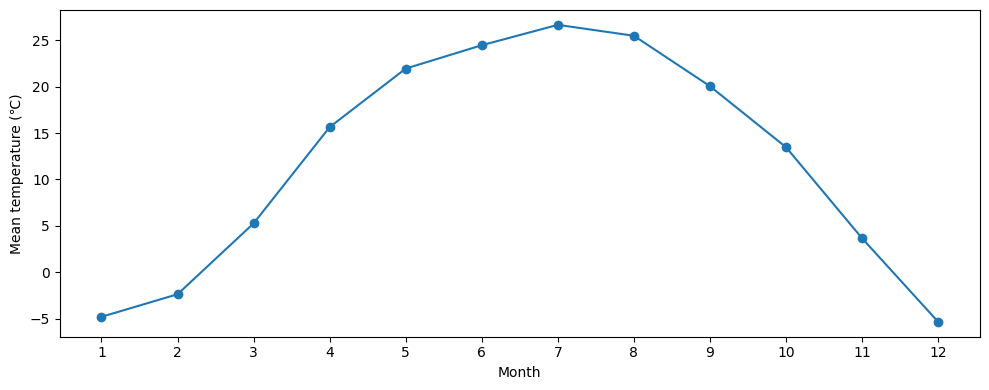

In [265]:
# 月平均气温变化图
monthly_mean_temp = beijing_temp.groupby('Month')['TEMP_C'].mean()
plt.figure(figsize=(10, 4))
plt.plot(monthly_mean_temp.index, monthly_mean_temp.values, marker='o')
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Mean temperature (℃)')
plt.show()


**4.3 [5 points]** Conduct at least 5 simple statistical checks with the variable, and report your findings.

In [268]:
# 全年日平均气温的相关统计量
print('均值(Mean):', round(beijing_temp['TEMP_C'].mean(), 2))
print('标准差(Standard deviation):', round(beijing_temp['TEMP_C'].std(), 2))
print('中位数(Median):', round(beijing_temp['TEMP_C'].median(), 2))
print('最小值(Minimum):', round(beijing_temp['TEMP_C'].min(), 2))
print('最大值(Maximum):', round(beijing_temp['TEMP_C'].max(), 2))
print('第一分位数(Q1):', round(beijing_temp['TEMP_C'].quantile(0.25), 2))
print('第三分位数(Q3):', round(beijing_temp['TEMP_C'].quantile(0.75), 2))
print('日平均气温最高的日期：')
print(beijing_temp.loc[
    beijing_temp['TEMP_C'] == beijing_temp['TEMP_C'].max(),
    ['DATE', 'TEMP_C']
])
print('日平均气温最低的日期：')
print(beijing_temp.loc[
    beijing_temp['TEMP_C'] == beijing_temp['TEMP_C'].min(),
    ['DATE', 'TEMP_C']
])

均值(Mean): 12.05
标准差(Standard deviation): 12.03
中位数(Median): 14.64
最小值(Minimum): -12.33
最大值(Maximum): 30.94
第一分位数(Q1): 0.22
第三分位数(Q3): 23.22
日平均气温最高的日期：
          DATE     TEMP_C
168 2012-06-17  30.944444
日平均气温最低的日期：
          DATE     TEMP_C
357 2012-12-23 -12.333333


        Mean   Std
Month             
1      -4.80  1.92
2      -2.37  2.65
3       5.27  4.61
4      15.65  3.24
5      21.95  2.36
6      24.47  2.47
7      26.67  1.91
8      25.49  2.29
9      20.05  1.99
10     13.47  3.16
11      3.66  3.14
12     -5.35  3.06


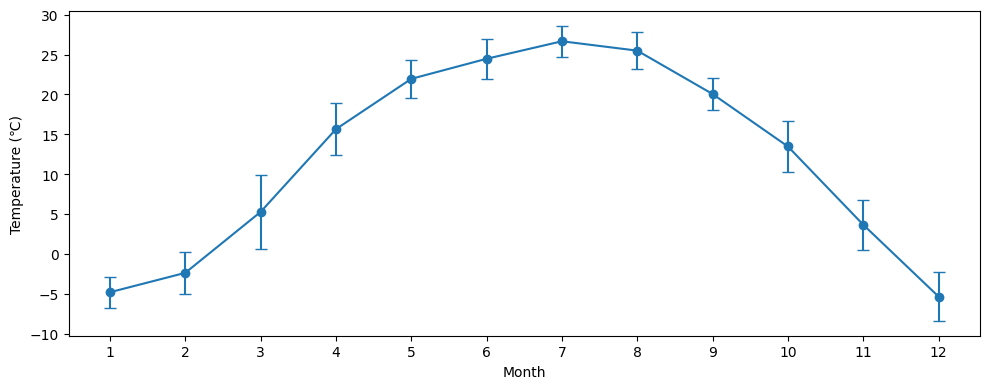

In [269]:
# 按月份计算日平均气温的均值和标准差
monthly_temp = beijing_temp.groupby('Month')['TEMP_C']
monthly_temp_stats = pd.DataFrame({
    'Mean': monthly_temp.mean(),
    'Std': monthly_temp.std()
})
print(monthly_temp_stats.round(2))

# 误差棒表示月平均值上下一个标准差
plt.figure(figsize=(10, 4))
plt.errorbar(
    monthly_temp_stats.index,
    monthly_temp_stats['Mean'],
    yerr=monthly_temp_stats['Std'],
    fmt='-o', capsize=4
)
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Temperature (℃)')
plt.show()


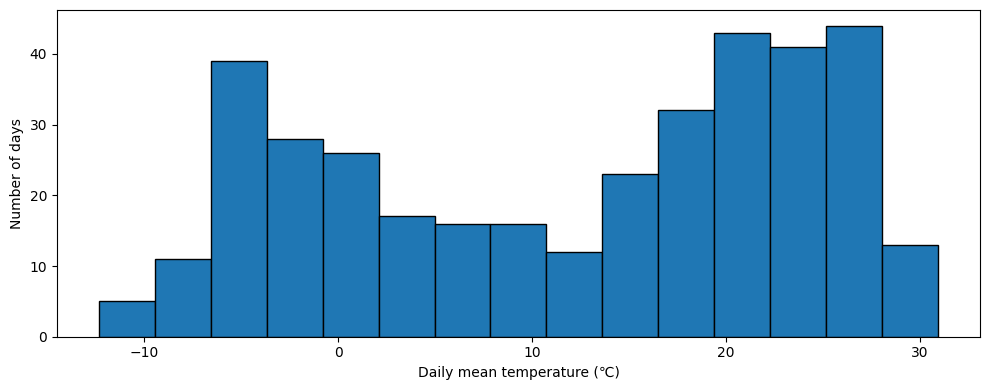

In [272]:
# 全年日平均气温的频数分布
plt.figure(figsize=(10, 4))
plt.hist(beijing_temp['TEMP_C'], bins=15, edgecolor='black')
plt.xlabel('Daily mean temperature (℃)')
plt.ylabel('Number of days')
plt.show()
